# UD1 — Anscombe y tiempos de respuesta de una web

**Pregunta del segundo ejemplo:** ¿una media de 280 ms demuestra que el 95 % de
las peticiones responde en 500 ms o menos?

Primero recordamos Anscombe, que ya se ha trabajado. Después usamos un único
servidor, una única ruta y un único fichero de peticiones. No comparamos campañas
ni necesitamos clasificar personas.

## Archivos que debes tener en esta misma carpeta

- `anscombe.csv`: 44 pares de valores de los cuatro conjuntos clásicos.
- `latencias_web.csv`: 1.000 peticiones HTTP sintéticas, ya generadas.
- Este notebook y la guía Markdown homónima.

Los datos **son archivos CSV**, no se descargan y no se generan ocultamente al
abrir el notebook. Copia la carpeta completa. Ejecuta de arriba abajo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
candidatos = [Path.cwd(), Path.cwd() / 'ud01-introduccion-big-data' / '02-ejemplos']
if '__file__' in globals():
    candidatos.insert(0, Path(__file__).resolve().parent)
BASE = next((p for p in candidatos if (p / 'anscombe.csv').is_file()
             and (p / 'latencias_web.csv').is_file()), None)
if BASE is None:
    raise FileNotFoundError('Faltan anscombe.csv o latencias_web.csv. Copia la carpeta completa de ejemplos y abre el notebook desde ella.')
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})

## 1. Recordatorio: Anscombe

**Fuente:** datos construidos clásicos de F. J. Anscombe (1973), documentados en
el [paquete datasets de R](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/anscombe.html).
No son medidas de nuestro servidor. Cada fila del CSV contiene el nombre del
conjunto y un par `(x, y)`. Son 11 observaciones por conjunto.

Objetivo: recordar que resúmenes casi iguales no implican gráficas iguales.

In [2]:
anscombe = pd.read_csv(BASE / 'anscombe.csv')
assert len(anscombe) == 44 and not anscombe.isna().any().any()
assert anscombe.groupby('conjunto').size().eq(11).all()
display(anscombe.head())
filas = []
for nombre, grupo in anscombe.groupby('conjunto', sort=False):
    pendiente, intercepto = np.polyfit(grupo.x, grupo.y, 1)
    filas.append({'conjunto': nombre, 'media_x': grupo.x.mean(), 'media_y': grupo.y.mean(),
                  'var_x': grupo.x.var(ddof=1), 'var_y': grupo.y.var(ddof=1),
                  'r_Pearson': grupo.x.corr(grupo.y), 'pendiente': pendiente, 'intercepto': intercepto})
resumen_anscombe = pd.DataFrame(filas).set_index('conjunto')
display(resumen_anscombe.round(2))

,conjunto,x,y
0,I,10,8.04
1,I,8,6.95
2,I,13,7.58
3,I,9,8.81
4,I,11,8.33


,media_x,media_y,var_x,var_y,r_Pearson,pendiente,intercepto
conjunto,,,,,,,
I,9.0,7.5,11.0,4.13,0.82,0.5,3.0
II,9.0,7.5,11.0,4.13,0.82,0.5,3.0
III,9.0,7.5,11.0,4.12,0.82,0.5,3.0
IV,9.0,7.5,11.0,4.12,0.82,0.5,3.0


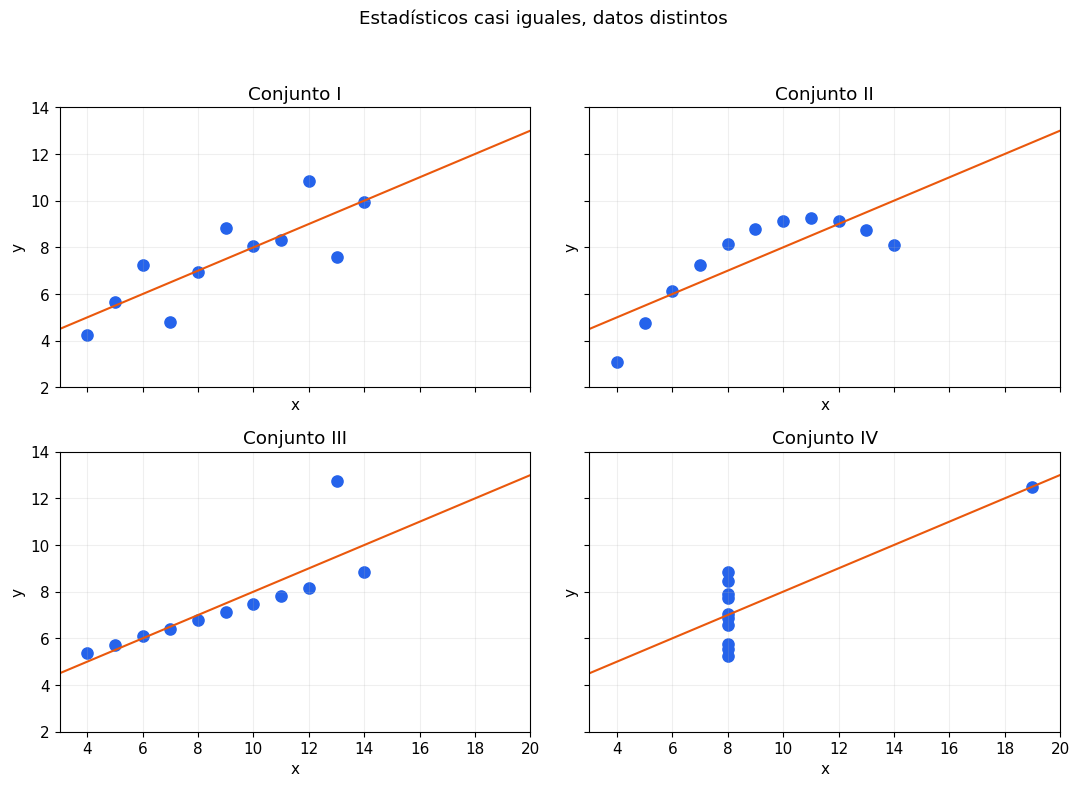

In [3]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for eje, (nombre, grupo) in zip(ejes.flat, anscombe.groupby('conjunto', sort=False)):
    xx = np.linspace(3, 20, 100)
    eje.scatter(grupo.x, grupo.y, color='#2563eb', s=65)
    eje.plot(xx, resumen_anscombe.loc[nombre, 'intercepto'] + resumen_anscombe.loc[nombre, 'pendiente'] * xx, color='#ea580c')
    eje.set(title=f'Conjunto {nombre}', xlabel='x', ylabel='y', xlim=(3, 20), ylim=(2, 14))
    eje.grid(alpha=0.2)
fig.suptitle('Estadísticos casi iguales, datos distintos')
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 2. Nuestro caso: ¿la web responde lo bastante rápido?

### Qué estamos estudiando

Tenemos la página de inicio de una web, `GET /inicio`. Queremos saber
cuánto tarda en responder a sus peticiones. El requisito de este ejercicio es:

> **Al menos el 95 % de las peticiones debe responder en 500 ms o menos.**

500 ms son medio segundo. En una muestra de 1.000 peticiones, deberían cumplir
al menos 950. Es un objetivo fijado para el ejemplo, no una ley universal.

### De dónde salen los datos

`latencias_web.csv` representa la salida que podría guardar un script cliente de
monitorización HTTP: una fila por petición y su tiempo de respuesta. Aquí lo
hemos **simulado**, sin conectarnos a un servidor real ni hacer peticiones de red.
El generador es `preparar_estadistica_web.py`, en esta misma carpeta.

La duración representa el tiempo desde enviar la petición hasta recibir la
respuesta completa. Los instantes son ficticios y las peticiones pueden solaparse.
Los tiempos se han simplificado a tres valores para poder comprobar las cuentas.

| Columna | Qué significa | Ejemplo / unidad |
|---|---|---|
| `request_id` | Identificador de esta petición, no de una persona. | 1 |
| `instante_peticion` | Momento en que empieza la petición. | Fecha y hora ficticias |
| `metodo` | Método HTTP solicitado. | GET |
| `ruta` | Recurso de la web que se solicita. | /inicio |
| `estado_http` | Estado devuelto al terminar. | 200: respuesta correcta |
| `duracion_ms` | Tiempo hasta recibir la respuesta completa. | Milisegundos |

**HTTP 200 no significa respuesta rápida.** Una petición puede terminar bien
y obligarnos a esperar diez segundos.

In [4]:
latencias = pd.read_csv(BASE / 'latencias_web.csv')
assert len(latencias) == 1000
assert latencias.request_id.is_unique
assert not latencias.isna().any().any()
assert latencias.duracion_ms.ge(0).all()
assert latencias.ruta.eq('/inicio').all()
assert latencias.estado_http.eq(200).all()
display(latencias.head(8))
print('Una fila por petición. Todas son GET /inicio y terminan con HTTP 200.')
print('Ejemplos de peticiones con cada una de las tres duraciones:')
display(latencias.sort_values('duracion_ms').groupby('duracion_ms', sort=True).head(1))

,request_id,instante_peticion,metodo,ruta,estado_http,duracion_ms
0,1,2026-10-15T09:00:00,GET,/inicio,200,1000
1,2,2026-10-15T09:00:01,GET,/inicio,200,1000
2,3,2026-10-15T09:00:02,GET,/inicio,200,100
3,4,2026-10-15T09:00:03,GET,/inicio,200,1000
4,5,2026-10-15T09:00:04,GET,/inicio,200,100
5,6,2026-10-15T09:00:05,GET,/inicio,200,100
6,7,2026-10-15T09:00:06,GET,/inicio,200,100
7,8,2026-10-15T09:00:07,GET,/inicio,200,100


Una fila por petición. Todas son GET /inicio y terminan con HTTP 200.
Ejemplos de peticiones con cada una de las tres duraciones:


,request_id,instante_peticion,metodo,ruta,estado_http,duracion_ms
16,17,2026-10-15T09:00:16,GET,/inicio,200,100
998,999,2026-10-15T09:16:38,GET,/inicio,200,1000
340,341,2026-10-15T09:05:40,GET,/inicio,200,10000


In [5]:
frecuencias = latencias.groupby('duracion_ms').size().rename('peticiones').to_frame()
frecuencias['porcentaje'] = 100 * frecuencias.peticiones / len(latencias)
display(frecuencias)
print('900 × 100 ms + 90 × 1.000 ms + 10 × 10.000 ms = 280.000 ms acumulados')
print('Media = 280.000 / 1.000 = 280 ms por petición')

,peticiones,porcentaje
duracion_ms,,
100,900,90.0
1000,90,9.0
10000,10,1.0


900 × 100 ms + 90 × 1.000 ms + 10 × 10.000 ms = 280.000 ms acumulados
Media = 280.000 / 1.000 = 280 ms por petición


In [6]:
t = latencias.duracion_ms
resumen_web = pd.Series({
    'Peticiones': len(t), 'Media (ms)': t.mean(), 'Mediana (ms)': t.median(),
    'Mínimo (ms)': t.min(), 'Máximo (ms)': t.max(), 'Rango (ms)': t.max() - t.min(),
    'Varianza muestral (ms²)': t.var(ddof=1), 'Desviación típica muestral (ms)': t.std(ddof=1),
    'P95 (ms)': t.quantile(0.95),
}, name='valor')
display(resumen_web.to_frame().round(2))

,valor
Peticiones,1000.00
Media (ms),280.00
Mediana (ms),100.00
Mínimo (ms),100.00
Máximo (ms),10000.00
Rango (ms),9900.00
Varianza muestral (ms²),1021621.62
Desviación típica muestral (ms),1010.75
P95 (ms),1000.00


### Decide antes de seguir

La media es **280 ms**, menor que 500 ms. La mediana es **100 ms**.

**¿Basta con eso para decir que el 95 % respondió en 500 ms o menos?**

El requisito habla de cuántas peticiones cumplen, no de la media ni de la mediana.
Predice el porcentaje usando la tabla de frecuencias antes de ejecutar la celda.

In [7]:
UMBRAL_MS = 500
OBJETIVO_PCT = 95
cumplen = int(t.le(UMBRAL_MS).sum())
lentas = len(t) - cumplen
porcentaje_cumple = 100 * cumplen / len(t)
p95 = float(t.quantile(0.95))
display(pd.DataFrame({
    'Comprobación': ['Peticiones totales', 'En 500 ms o menos', 'Más de 500 ms', 'Porcentaje que cumple', 'Objetivo mínimo (%)'],
    'Valor': [len(t), cumplen, lentas, porcentaje_cumple, OBJETIVO_PCT],
}))
print(f'Resultado: {cumplen} de {len(t)} = {porcentaje_cumple:.0f} %. Objetivo: {OBJETIVO_PCT} %.')
print('¿Cumple el requisito?', porcentaje_cumple >= OBJETIVO_PCT)
print(f'P95 = {p95:.0f} ms: en esta muestra, al menos el 95 % está en 1.000 ms o menos; en 500 ms solo cumple el 90 %.')
assert np.isclose(t.mean(), 280) and t.median() == 100
assert cumplen == 900 and lentas == 100 and porcentaje_cumple == 90 and p95 == 1000

,Comprobación,Valor
0,Peticiones totales,1000.0
1,En 500 ms o menos,900.0
2,Más de 500 ms,100.0
3,Porcentaje que cumple,90.0
4,Objetivo mínimo (%),95.0


Resultado: 900 de 1000 = 90 %. Objetivo: 95 %.
¿Cumple el requisito? False
P95 = 1000 ms: en esta muestra, al menos el 95 % está en 1.000 ms o menos; en 500 ms solo cumple el 90 %.


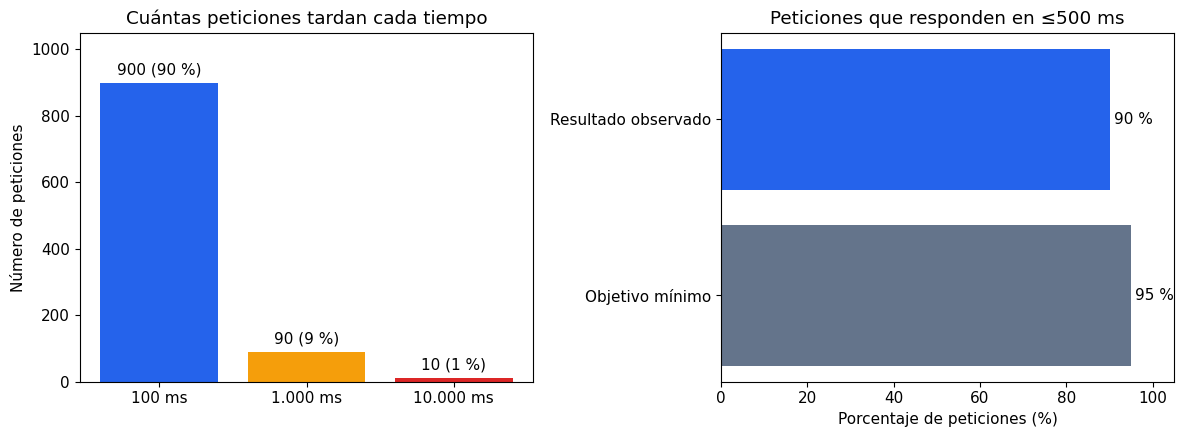

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
etiquetas = [f'{d:,} ms'.replace(',', '.') for d in frecuencias.index]
barras = ejes[0].bar(etiquetas, frecuencias.peticiones, color=['#2563eb', '#f59e0b', '#dc2626'])
ejes[0].bar_label(barras, labels=[f'{n} ({p:.0f} %)' for n, p in zip(frecuencias.peticiones, frecuencias.porcentaje)], padding=4)
ejes[0].set(title='Cuántas peticiones tardan cada tiempo', ylabel='Número de peticiones', ylim=(0, 1050))
ejes[1].barh(['Objetivo mínimo', 'Resultado observado'], [OBJETIVO_PCT, porcentaje_cumple], color=['#64748b', '#2563eb'])
ejes[1].set(title='Peticiones que responden en ≤500 ms', xlabel='Porcentaje de peticiones (%)', xlim=(0, 105))
for y, v in enumerate([OBJETIVO_PCT, porcentaje_cumple]):
    ejes[1].text(v + 1, y, f'{v:.0f} %', va='center')
fig.tight_layout()
plt.show()

### Qué acabamos de demostrar

- La media de 280 ms está bien calculada, pero no responde al requisito.
- El 90 % responde en 100 ms; **100 de las 1.000 peticiones** tardan más de 500 ms.
- El objetivo exigía que cumplieran al menos 950. Solo cumplen 900: **no se alcanza**.
- El P95 es un segundo. Un percentil expresa un límite para una fracción de las
  observaciones; no significa que todas tarden ese tiempo.
- Las peticiones lentas son datos reales dentro de nuestra simulación, no errores
  que podamos borrar para mejorar la nota del servidor.

No sabemos por qué son lentas. Harían falta otras medidas para investigar red,
base de datos, bloqueos o carga. No se deduce la causa de una media.

### ¿Y si quitamos las lentas?

Quedarían 900 filas, media 100 ms y cumplimiento del 100 % **entre las filas
conservadas**. No habríamos arreglado la web: habríamos ocultado las 100 peticiones
que incumplían. Detectar un dato extremo o lento no autoriza a borrarlo.

## 3. Trabajo con el CSV (parejas, 20 minutos)

1. Abre `latencias_web.csv` y explica las seis columnas con tus palabras.
2. Comprueba cuántas filas cumplen `duracion_ms <= 500`. Calcula su porcentaje.
3. Explica por qué media y mediana no bastan para comprobar el requisito.
4. Elige una gráfica y escribe qué muestra: número de peticiones, duración o porcentaje.
5. Escribe qué datos conservarías para investigar las peticiones lentas.

## 4. Matemáticas del mismo caso (15–20 minutos)

- **Conjuntos:** forma el conjunto de `request_id` con HTTP 200 y el de peticiones
  de más de 500 ms. ¿Cuántas pertenecen a ambos? ¿Respuesta correcta implica rápida?
- **Lógica:** escribe una regla `SI ... ENTONCES ...` que marque una petición lenta,
  sin eliminarla. Distingue marcar cada fila de comprobar el 95 % de toda la muestra.
- **Complejidad:** para contar lentas basta recorrer n filas. Para calcular un
  percentil exacto por ordenación, un enfoque habitual necesita ordenar. ¿Por qué
  no conviene comparar cada petición con todas las demás?

### Cierre individual

> La media responde a esta pregunta: …
>
> Para comprobar nuestro requisito necesito calcular: …
>
> Un dato que debo conservar aunque me empeore el indicador es: …